,prompt,N,H,control_type,lam,n_inner,sample_mode,warmstart,drift_detach,r_unc,r_ctrl,delta_r,ctrl_energy,time_unc_s,time_ctrl_s
0,a sunset,10,4,mpc,25000.0,5,flow_map2,True,True,0.290388,0.416704,0.126316,20.785162,3.462217,63.917029


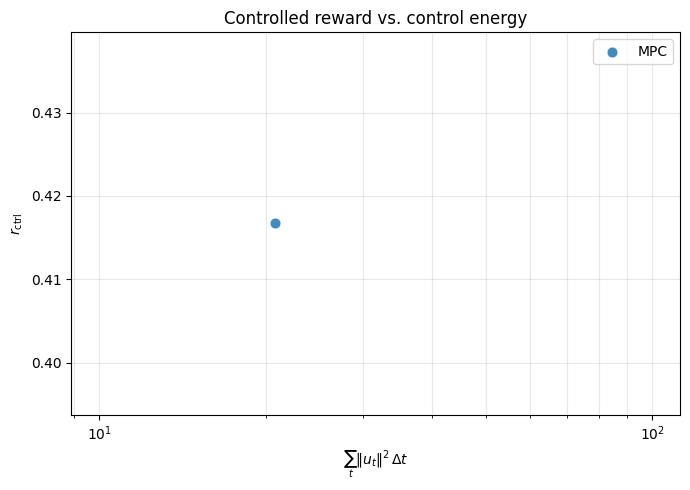

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('results/summary.csv')
display(df)

fig, ax = plt.subplots(figsize=(7, 5))
colors = {"mpc": "tab:blue", "fmrg": "tab:orange"}

for control_type, sub in df.groupby("control_type"):
    ax.scatter(
        sub["ctrl_energy"], sub["r_ctrl"],
        label=control_type.upper(),
        color=colors.get(control_type, "gray"),
        s=60,
        alpha=0.85,
        edgecolors="white",
        linewidths=0.5,
    )

ax.set_xscale("log")
ax.set_xlabel(r"$\sum_t \|u_t\|^2\,\Delta t$")
ax.set_ylabel(r"$r_{\mathrm{ctrl}}$")
ax.set_title("Controlled reward vs. control energy")
ax.legend()
ax.grid(True, alpha=0.3, which="both")
plt.tight_layout()
plt.show()